<a href="https://colab.research.google.com/github/Ekimxii/fitness_pose_tracker/blob/main/form_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Form model

Trained on the Kaggle data only, for now. The model looks at one frame's 12 joint angles (from `features.py`) and predicts which of the 10 poses it shows: one of the 5 exercises (squats, push-ups, pull-ups, sit-ups, jumping jacks), up or down.

Next step: apply it to QEVD's squat and push-up clips, once `qevd_data/` exists (`python qevd_to_table.py`).

In [2]:
# Setup: the Kaggle data, and our shared features.py and reps.py (Colab downloads them; locally they're already here)
import os
for module in ["features.py", "reps.py"]:
    if not os.path.exists(module):
        !wget -q https://raw.githubusercontent.com/Ekimxii/fitness_pose_tracker/main/{module}

import kagglehub
import numpy as np
import pandas as pd
from features import ALL_ANGLES
from reps import load_training_data

# One row per frame: 12 joint angles, plus "pose" (e.g. "squats_down"), "exercise" and "position"
data = load_training_data(kagglehub.dataset_download("muhannadtuameh/exercise-recognition"))
FEATURES = list(ALL_ANGLES)

100%|██████████| 1.07M/1.07M [00:00<00:00, 56.4MB/s]

Extracting files...


In [3]:
# train test split
# 80% of frames to train on, 20% held back to test, with every pose in the same proportions in both.
# A random split is fine for this data: neighbouring frames in the Kaggle files are barely more alike
# than random frames of the same pose (24 vs 27 degrees average difference), so near-copies don't leak.
from sklearn.model_selection import train_test_split

train, test = train_test_split(data, test_size=0.2, stratify=data["pose"], random_state=0)
print(f"{len(train)} training frames, {len(test)} test frames, {data['pose'].nunique()} poses")

1097 training frames, 275 test frames, 10 poses


In [4]:
# train with Kaggle data
# A random forest, as in form_analysis.ipynb (chart 8) and the rep counter
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=150, random_state=0).fit(train[FEATURES], train["pose"])
predicted = model.predict(test[FEATURES])

def exercise_of(poses):   # "jumping_jacks_down" -> "jumping_jacks"
    return pd.Series(poses).str.rsplit("_", n=1).str[0].to_numpy()

print(f"pose right (exercise and up/down): {(predicted == test['pose']).mean():.0%}")
print(f"exercise right (ignoring up/down): {(exercise_of(predicted) == test['exercise']).mean():.0%}")
print(f"chance (always the most common pose): {test['pose'].value_counts(normalize=True).max():.0%}")

pose right (exercise and up/down): 72%
exercise right (ignoring up/down): 74%
chance (always the most common pose): 14%


In [5]:
# apply model on QEVD

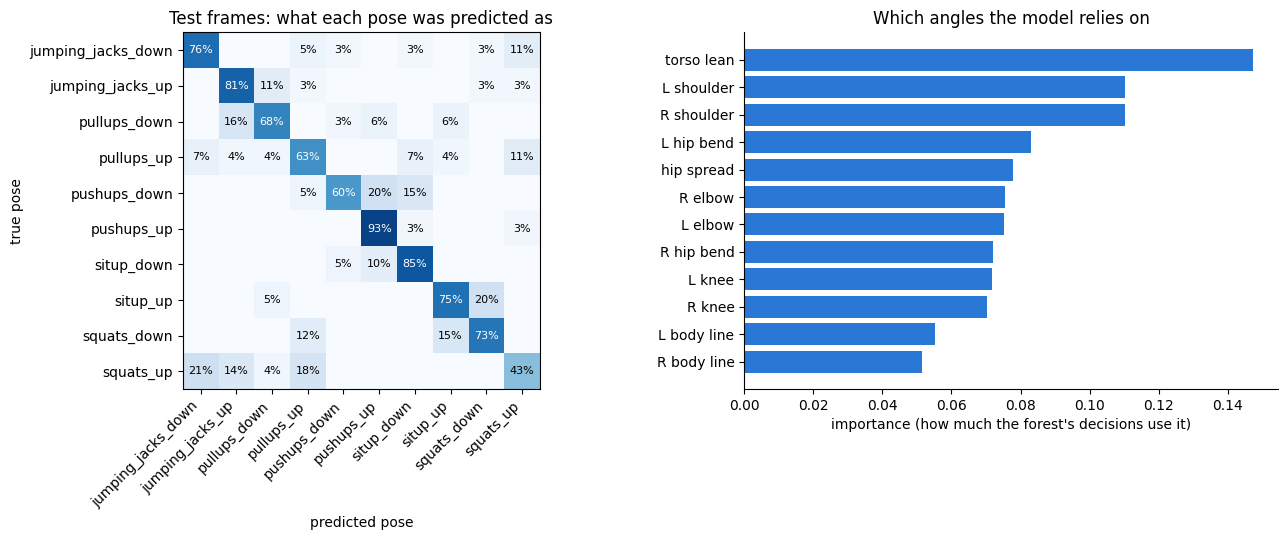

In [6]:
# results visualization
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

poses = sorted(data["pose"].unique())
share = confusion_matrix(test["pose"], predicted, labels=poses, normalize="true")   # each row adds up to 100%

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
ax1.imshow(share, cmap="Blues", vmin=0, vmax=1)
ax1.set_xticks(range(len(poses)), poses, rotation=45, ha="right")
ax1.set_yticks(range(len(poses)), poses)
for (r, c), v in np.ndenumerate(share):
    if v >= 0.01:
        ax1.text(c, r, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white" if v > 0.5 else "black")
ax1.set(xlabel="predicted pose", ylabel="true pose", title="Test frames: what each pose was predicted as")

importance = pd.Series(model.feature_importances_, index=[ALL_ANGLES[c] for c in FEATURES]).sort_values()
ax2.barh(importance.index, importance.values, color="#2a78d6")
ax2.set(xlabel="importance (how much the forest's decisions use it)", title="Which angles the model relies on")
ax2.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

random forest  pose right: 74%   exercise right: 76%
XGBoost        pose right: 74%   exercise right: 76%


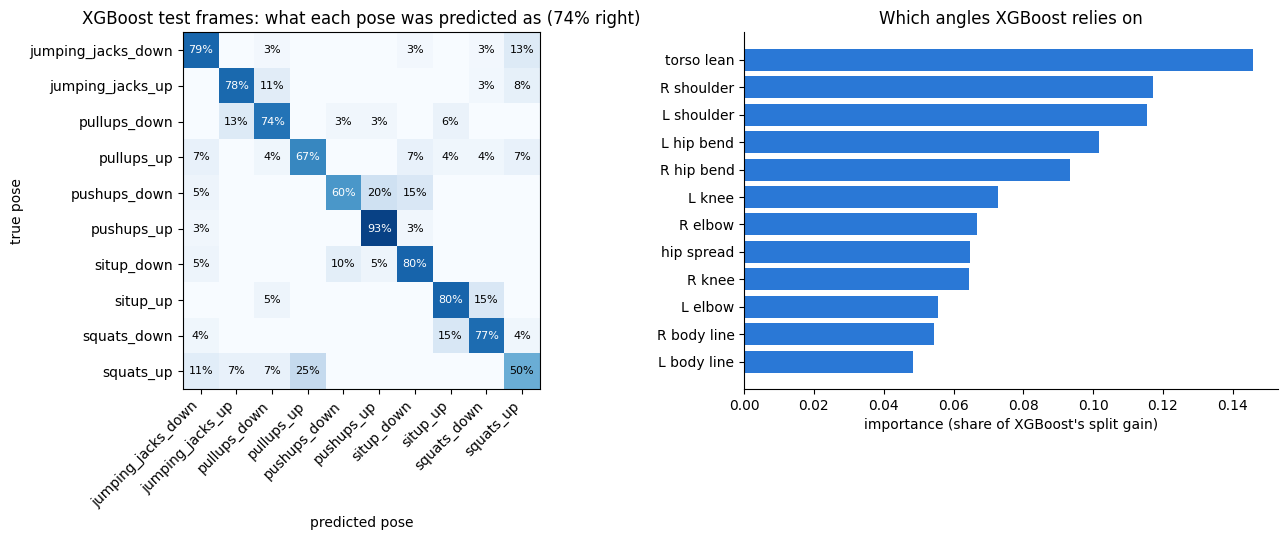

In [8]:
# XGBoost: train, compare with the random forest, and visualize (one cell)
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix

# Train: XGBoost needs the 10 pose names as numbers 0–9, so encode them and decode the predictions
enc = LabelEncoder().fit(data["pose"])
xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1,
                    subsample=0.8, colsample_bytree=0.8,
                    eval_metric="mlogloss", random_state=0)
xgb.fit(train[FEATURES], enc.transform(train["pose"]))
predicted_xgb = enc.inverse_transform(xgb.predict(test[FEATURES]))

# Compare with the random forest on the same test frames
for name, pred in [("random forest", predicted), ("XGBoost", predicted_xgb)]:
    print(f"{name:13}  pose right: {(pred == test['pose']).mean():.0%}   "
          f"exercise right: {(exercise_of(pred) == test['exercise']).mean():.0%}")

# Visualize: confusion matrix (left) and which angles XGBoost relies on (right)
poses = sorted(data["pose"].unique())
share_xgb = confusion_matrix(test["pose"], predicted_xgb, labels=poses, normalize="true")   # rows add up to 100%

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
ax1.imshow(share_xgb, cmap="Blues", vmin=0, vmax=1)
ax1.set_xticks(range(len(poses)), poses, rotation=45, ha="right")
ax1.set_yticks(range(len(poses)), poses)
for (r, c), v in np.ndenumerate(share_xgb):
    if v >= 0.01:
        ax1.text(c, r, f"{v:.0%}", ha="center", va="center", fontsize=8,
                 color="white" if v > 0.5 else "black")
acc = (predicted_xgb == test["pose"]).mean()
ax1.set(xlabel="predicted pose", ylabel="true pose",
        title=f"XGBoost test frames: what each pose was predicted as ({acc:.0%} right)")

importance_xgb = pd.Series(xgb.feature_importances_,
                           index=[ALL_ANGLES[c] for c in FEATURES]).sort_values()
ax2.barh(importance_xgb.index, importance_xgb.values, color="#2a78d6")
ax2.set(xlabel="importance (share of XGBoost's split gain)", title="Which angles XGBoost relies on")
ax2.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
